# Projet Recherche Opérationnelle

**Classe :** FISA A3 - Informatique  
**Groupe :** NOIRET Robin, LALOUANI Jalil, KLEBER Mattéo, CAPARROS Martin, UPJOHN Max  
**Période :** 03/2026 - 04/2026

---


# 1 - Contexte & Identification du problème

## 1.1 Identification du problème

### Périmètre de l'étude
L'étude se concentre sur **une tournée quotidienne**, réalisée par un **unique véhicule**, au départ et au retour d'**un dépôt unique**. Les aspects tels que la flotte multi-véhicules, la gestion des stocks au dépôt ou la planification sur plusieurs jours sont volontairement exclus du périmètre afin de concentrer l'analyse sur la structure combinatoire du routage sous contraintes.

### Reformulation du besoin
Si on réfléchis de manière plus large, ce problème revient à **déterminer l'ordre de visite d'un ensemble de points d'arrêt** (livraisons et collectes) qui permette de réaliser l'intégralité de la tournée dans les meilleures conditions possibles, tout en respectant des règles de précédence et des restrictions de circulation imposées par le réseau routier.

### Objectif de l'étude
L'objectif d'optimisation retenu est la **minimisation de la distance totale parcourue** sur l'ensemble de la tournée. Ce critère sert de proxy direct aux enjeux soulevés par l'ADEME : réduction de la consommation énergétique, des émissions de gaz à effet de serre, et du temps de trajet du véhicule.

### Contraintes sélectionnées
Dans notre cas, nous avons ajouté 2 contraintes à ce problème : 
- **Coût ou restriction de passage sur certaines arêtes** : Certaines routes peuvent être plus coûteuses ou interdites (par exemple, travaux ou routes bloquées).
- **Dépendances entre visites** : Une ville ne peut être visitée qu'après en avoir visité une autre (par exemple, une livraison doit précéder une collecte).

### Rattachement à un problème connu
Ce problème est une **variante du problème du voyageur de commerce** (*Travelling Salesman Problem*, TSP)[$^5$](#52-références-scientifiques) [$^6$](#52-références-scientifiques). La formulation classique du TSP, à savoir trouver le cycle hamiltonien de poids minimal dans un graphe pondéré correspond exactement à la structure de notre tournée. Les deux contraintes que nous ajoutons (arêtes interdites/coûteuses et précédences) en font une instance enrichie.



</br>

## 1.2 Cas d'application

Dans le cadre de l'appel à projets de l'**ADEME** sur la mobilité intelligente, notre bureau d'études **CesiCDP** a choisi de tester ses algorithmes d'optimisation sur un scénario concret et d'actualité : **la logistique de l'économie circulaire en milieu urbain dense**.

### Scénario expérimental
Un véhicule logistique part d'un centre de tri situé en périphérie (notre dépôt).</br> Sa mission quotidienne est double :
1. **Livrer** des équipements volumineux reconditionnés (ex: gros électroménager, pompes à chaleur) dans divers points relais ou chez des particuliers.

2. **Collecter** les anciens appareils en fin de vie (DEEE) pour les rapatrier au centre de tri afin d'y être recyclés.

### Intégration de nos contraintes de test
Pour valider la robustesse de notre modèle face à la réalité opérationnelle, notre environnement de simulation intègre deux contraintes physiques et réglementaires strictes :

* **Dépendances entre visites :** Il est physiquement impossible de charger un ancien équipement encombrant si le nouveau n'a pas encore été déchargé. L'algorithme doit donc garantir une **précédence** : la livraison d'un point A doit obligatoirement être effectuée avant la collecte au point B associé.</br></br>

* **La difficulté & l'inaccessibilité des routes :** Le réseau routier simulé intègre les nouvelles politiques d'urbanisme. L'algorithme devra trouver le trajet optimal en prenant en compte :
    * Des routes à coût majoré (zones de travaux urbains causant des détours ou des ralentissements).
    * Des routes strictement interdites (Zones à Faibles Émissions - ZFE inaccessibles, ou rues piétonnes/ponts avec restrictions de gabarit).

</br>

**Ce document pose les fondations théoriques de notre problème.** </br></br> La modélisation de ce problème de routage sous nos contraintes spécifiques choisies ainsi que la démonstration de son **explosion combinatoire** (NP-difficulté) justifieront, pour la suite du projet, l'implémentation de méthodes de résolution **approchées** capables de fournir des plans de tournée viables dans des temps de calcul optimisés.



# 2 - Définition mathématique du problème

## 2.1 Données du problème

On modélise le réseau routier par un graphe orienté pondéré :

$$G = (V, E, c')$$

avec :

- $V = \{v_0, v_1, \ldots, v_n\}$ : l'ensemble des **nœuds** (villes), où $v_0$ désigne le **dépôt** (point de départ et d'arrivée)
- $E = \{(i,j) \mid i \in V,\ j \in V,\ i \neq j\}$ : l'ensemble des **arêtes** (routes)
- $c'_{ij} = \alpha_{ij} \cdot c_{ij}$ : la **fonction de coût**, associant à chaque arête une distance. On ajoute une notion de coefficient (BigM)
> $\quad \quad \quad \alpha_{ij} = \begin{cases} 1 & \text{route classique} \\ [2,\ 10] & \text{route coûteuse} \\ [1000,\ 10000] & \text{route interdite} \end{cases}$

On définit également les ensembles suivants pour modéliser nos contraintes supplémentaires :

- $F \subseteq E$ : l'ensemble des **arêtes interdites** (routes bloquées, trop coûteuses ou inaccessibles)
- $D \subseteq V^2$ : l'ensemble des **paires de dépendance** de la forme $(i, j)$, signifiant que la ville $i$ doit être visitée avant la ville $j$ (livraison avant collecte)

## 2.2 Variables de décision

**Variables binaires de sélection des arêtes :**

$$x_{ij} \in \{0, 1\} \quad \forall (i,j) \in E$$

$x_{ij} = 1$ si et seulement si l'arête $(i,j)$ est empruntée dans la tournée, $0$ sinon.

**Variables de position (rang dans la tournée) :**

$$p_i \in \{1, \ldots, n\} \quad \forall i \in V \setminus \{v_0\}$$

$p_i$ représente le rang (ordre de passage) de la ville $i$ dans la tournée.

## 2.3 Fonction objectif

On cherche à **minimiser la distance totale** de la tournée :

$$\min \sum_{i \in V} \sum_{\substack{j \in V \\ j \neq i}} c'_{ij} \cdot x_{ij}$$

## 2.4 Contraintes

#### (C1) Chaque ville est visitée exactement une fois

$$\sum_{j \in V,\ j \neq i} x_{ij} = 1 \quad \forall i \in V  \quad \quad \quad

\sum_{i \in V,\ i \neq j} x_{ij} = 1 \quad \forall j \in V$$

#### (C2) Coût ou restriction de passage sur certaines arêtes

Certaines routes peuvent être dégradées (travaux, détours) ou totalement inaccessibles. Plutôt qu'une interdiction stricte, on modélise ces restrictions par un **coefficient de pénalité** $\alpha_{ij}$ appliqué au coût de chaque arête :

$$c'_{ij} = \alpha_{ij} \cdot c_{ij}$$

$$\alpha_{ij} = \begin{cases} 1 & \text{route classique} \\ [2,\ 10] & \text{route coûteuse} \\ [1000,\ 10000] & \text{route interdite} \end{cases}$$

> **Note :** Les arêtes "interdites" ne sont pas exclues par une contrainte dure, mais leur coût ajusté garantit qu'elles ne seront jamais empruntées par une solution optimale, étant donné l'échelle classique des coûts ($c_{ij} \in [1, 10]$).

#### (C3) Contraintes de dépendances de visite

Pour chaque paire de dépendance $(i, j) \in D$, la ville $i$ doit être visitée **avant** la ville $j$ :

$$p_i + 1 \leq p_j \quad \forall (i,j) \in D$$

> **Note :** Cette formule garantit un écart d'au moins une position entre les deux villes dans l'ordre de visite.

#### (C4) Élimination des sous-tours — Formulation MTZ

Pour éliminer les sous-tours (circuits ne passant pas par le dépôt), on utilise la formulation de Miller-Tucker-Zemlin (MTZ)[$^7$](#52-références-scientifiques) [$^8$](#52-références-scientifiques)  :

$$p_i - p_j + n \cdot x_{ij} \leq n - 1 \quad \forall (i,j) \in E,\ i \neq v_0,\ j \neq v_0$$

**Explication :**
- Si l'arête $(i,j)$ est utilisée ($x_{ij} = 1$) : la contrainte devient $p_i - p_j \leq -1$, soit $p_j \geq p_i + 1$. La ville $j$ est donc visitée **immédiatement après** la ville $i$ dans la tournée, ce sont donc deux villes consécutives. (cette contrainte représente l'élimination des sous-tours et non la dépendance de visite)
- Si l'arête $(i,j)$ n'est pas utilisée ($x_{ij} = 0$) : la contrainte devient $p_i - p_j \leq n - 1$, ce qui est toujours satisfait puisque les rangs appartiennent à $\{1, \dots, n\}$. La contrainte est relâchée.

## 2.5 Récapitulation (programmation linéaire)

On formule le problème comme un **programme linéaire en nombres entiers** (*Integer Linear Programming*, ILP). Les variables $x_{ij}$ sont binaires et les variables $p_i$ sont entières. Toutes les contraintes sont linéaires en ces variables.

$$
\text{PL} : \begin{cases}
\min & \displaystyle\sum_{i \in V} \sum_{\substack{j \in V \\ j \neq i}} c'_{ij} \cdot x_{ij} \\[10pt]
\ & \displaystyle\sum_{j \in V,\, j \neq i} x_{ij} = 1 \quad \forall i \in V \quad \text{(C1a)} \\[10pt]
& \displaystyle\sum_{i \in V,\, i \neq j} x_{ij} = 1 \quad \forall j \in V \quad \text{(C1b)} \\[10pt]
& p_i + 1 \leq p_j \quad \forall (i,j) \in D \quad \text{(C3)} \\[10pt]
& p_i - p_j + n \cdot x_{ij} \leq n - 1 \quad \forall (i,j) \in E,\ i \neq v_0,\ j \neq v_0 \quad \text{(C4)} \\[10pt]
& x_{ij} \in \{0, 1\} \\[10pt]
& p_i \in \{1, \ldots, n\} \\[10pt]
\end{cases}
$$

# 3 - Analyse de la complexité

La justification de la complexité de notre problème est primordiale pour orienter nos futurs choix d'implémentation. Pour ce faire, nous allons procéder par étapes, en partant d'un problème fondamental de la théorie des graphes pour arriver à notre cas d'usage logistique.

## 3.1. Le point de départ : Le problème du Cycle Hamiltonien (HC)

Le problème du Cycle Hamiltonien consiste à déterminer si, dans un graphe donné, il existe un cycle passant par chaque sommet exactement une fois.Ce problème de décision a été formellement classé comme NP-complet par Richard M. Karp en 1972 (il fait partie de ses 21 problèmes originaux). Cela signifie qu'il n'existe, à ce jour, aucun algorithme capable de le résoudre en un temps polynomial.

Référence : Karp, R. M. (1972). Reducibility among combinatorial problems. In Complexity of computer computations (pp. 85-103). Springer, Boston, MA.[$^{10}$](#52-références-scientifiques)

## 3.2. Preuve de la complexité du TSP par réduction polynomiale

Le problème de décision du Voyageur de Commerce (TSP) consiste à savoir s'il existe une tournée visitant toutes les villes avec un coût total inférieur ou égal à une limite $L$. Nous pouvons démontrer que le TSP est au moins aussi difficile que le Cycle Hamiltonien par une réduction polynomiale ($HC \leq_p TSP$). Soit une instance du problème du Cycle Hamiltonien définie par un graphe $G = (V, E)$. Nous construisons une instance du TSP de la manière suivante : Nous créons un graphe complet $G' = (V, E', c)$ ayant les mêmes sommets que $G$.Nous définissons la fonction de coût $c_{ij}$ pour chaque arête $(i, j)$ dans $E'$ :$$c_{ij} = \begin{cases} 1 & \text{si } (i, j) \in E \\ 2 & \text{si } (i, j) \notin E \end{cases}$$ Nous fixons notre limite de coût à $L = |V|$ (le nombre de sommets). Équivalence :Si $G$ possède un cycle hamiltonien, alors en suivant les mêmes arêtes dans $G'$, chaque arête aura un coût de $1$. Le coût total de la tournée sera exactement $|V|$. Inversement, si $G'$ possède une tournée de coût inférieur ou égal à $|V|$, cela signifie que la tournée n'emprunte que des arêtes de coût $1$ (puisqu'il y a $|V|$ arêtes dans la tournée). Donc, toutes ces arêtes existent dans le graphe d'origine $G$, formant ainsi un cycle hamiltonien.La transformation du graphe $G$ en $G'$ se fait en temps polynomial (en parcourant toutes les paires de sommets, soit $O(|V|^2)$). Le problème HC se réduisant polynomialement au problème TSP, le TSP est donc NP-complet.

## 3.3. Application à notre problème d'optimisation

Notre modélisation, qui répond aux exigences de l'ADEME, inclut des restrictions d'arêtes et des contraintes de précédence. Il s'agit d'une variante du problème de voyageur du commerce.Pour prouver que notre problème d'optimisation est NP-difficile, nous utilisons le principe de restriction : Considérons une instance de notre problème logistique où nous relâchons volontairement nos contraintes spécifiques : Aucune arête n'est interdite : $E_{interdit} = \emptyset$ Aucune dépendance n'est requise entre les villes : $P = \emptyset$ Dans ces conditions restrictives, notre problème devient strictement identique au TSP d'optimisation classique. Puisque notre problème général contient le TSP (qui est NP-difficile) comme un cas particulier, notre problème est par définition au moins aussi complexe que le TSP.

# 4 - Bibliographie

1. 
2. [**Problème de vendeur de voyages. (s. d.).** *Google For Developers.*](https://developers.google.com/optimization/routing/tsp?hl=fr) - visité le 09/04/2026
3. [**Problème d’itinéraire. (s. d.).** *Google For Developers.*](https://developers.google.com/optimization/routing/vrp?hl=fr) - visité le 09/04/2026
4. 
5. [**Dantzig, G. B., & Ramser, J. H. (1959).** *The Truck Dispatching Problem*. Management Science, 6(1), 80-91.](https://pubsonline.informs.org/doi/10.1287/mnsc.6.1.80)
6. [**Miller, C. E., Tucker, A. W., & Zemlin, R. A. (1960).** *Integer Programming Formulation of Traveling Salesman Problems*. Journal of the ACM (JACM), 7(4), 326-329.](https://dl.acm.org/doi/10.1145/321043.321046)
7. [**Diego. (2020, 24 juin).** *Traveling Salesman Problem (TSP) with Miller-Tucker-Zemlin (MTZ) in CPLEX/OPL – CoEnzyme.*](https://co-enzyme.fr/blog/traveling-salesman-problem-tsp-in-cplex-opl-with-miller-tucker-zemlin-mtz-formulation/)
8. [**Teaching Integer Programming Formulations Using the Traveling Salesman Problem. (2003).** *SIAM REVIEW, 4.*](https://mate.unipv.it/~gualandi/famo2conti/papers/teaching_tsp.pdf)
9. [**Garey, M. R., & Johnson, D. S. (1979).** *Computers and Intractability: A Guide to the Theory of NP-Completeness. W. H. Freeman & Co.*](https://perso.limos.fr/~palafour/PAPERS/PDF/Garey-Johnson79.pdf)
10. [**Karp, R. M. (1972).** *Reducibility among combinatorial problems*. In Complexity of computer computations (pp. 85-103). Springer, Boston, MA.](https://www.cs.umd.edu/~gasarch/BLOGPAPERS/Karp.pdf)

____

# 5 - Méthodes de résolution

In [1]:
from pulp import *                                  # Modélisation et résolution PLNE
import numpy as np                                  # Calcul numérique et tableaux
from scipy.spatial.distance import cdist            # Calcul vectorisé des distances
import matplotlib.pyplot as plt                     # Visualisation du graphe et des tournées
from matplotlib.collections import LineCollection   # Tracer efficacement plusieurs arêtes à la fois
import time                                         # Mesure des temps d'exécution
from matplotlib.lines import Line2D                 # Lignes personnalisées pour la légende
from ipywidgets import IntProgress                  # Barre de progression
from IPython.display import display                 # Affichage des widgets
import pandas as pd                                 # Manipulation de données et DataFrame

### Fonctions utiles

In [2]:
COULEURS = {
    'alpha':      '#1E88E5',
    'beta':       '#43A047',
    'rho':        '#FFC107',
  
    'optimum':    '#E53935',
    'filigrane':  '#B0BEC5',
    'travaux':    '#FFC107',
    'interdit':   '#E53935',
    'dependance': '#43A047',
    'sommet':     '#1565C0',
    'depot':      '#E53935',
    'tournee':    '#1E88E5',
    'label_dist': '#90CAF9',
}
MARQUEUR = 'o'
MARQUEUR_DEBUT = '^'

Afin de générer des **instances aléatoires**, nous avons implémenté une fonction dédié permettant d'ajuster nos différents paramètres mais également de permettre un comportement **reproductible**. La fonction ```'generer_instance'``` nous permet de faire varier différentes choses : 
- **n** : nombre de sommets de l'instance généré
- **x_max** : limite haute des coordonnées x
- **y_max** : limite haute des coordonnées y
- **seed** : graine aléatoire pour assurer la reproductibilité des instances
- **pct_travaux** : pourcentage d'arêtes en travaux
- **pct_interdites** : pourcentage d'arêtes interdites
- **pct_dependances** : pourcentage de dépendances de visite
- **coef_travaux** :  intervalle des coefficients multiplicateurs appliqués aux arêtes en travaux
- **coef_interdit** :  intervalle des coefficients multiplicateurs appliqués aux arêtes interdites

<br></br>
Au niveau du fonctionnement interne de cette fonction on a différentes phases : 
1. **génération de coordonnées** : cette partie permet de générer des tuples compris dans l'interval définis grace à ```x_max``` et ```y_max```.
2. **calcul des distances** : basé sur ces coordonnées on vient appliqué la ```cdist``` de la bibliothèque ```scipy``` qui calcule les distances par paire entre 2 points. Cette partie nous permet de respecter l'inégalité triangulaire ($d(i, j) \leq d(i, k) + d(k, j) \quad \forall i, j, k$)
3. **applications des contraintes supplémentaires** : cette phase modifie la matrice de coûts de base en modélisant les restrictions du réseau routier.

In [3]:
def generer_instance(
    n,
    x_max=500,
    y_max=500,
    seed=None,
    pct_travaux=0.1,
    pct_interdites=0.05,
    pct_dependances=0.05,
    coef_travaux_min=1.0,
    coef_travaux_max=2.0,
    coef_interdit_min=10000,
    coef_interdit_max=100000,
):
    if seed is not None:
        np.random.seed(seed)
    
    x_coords = np.random.randint(50, x_max, size=n)
    y_coords = np.random.randint(50, y_max, size=n)
    coords = np.column_stack((x_coords, y_coords))

    dist = np.round(cdist(coords, coords, metric='euclidean') * 100).astype(int)
    couts = dist.copy()

    aretes = [(i, j) for i in range(n) for j in range(i + 1, n)]
    if not aretes:
        return coords.tolist(), couts.tolist(), [], [], []

    pct_travaux = pct_travaux / 100 if pct_travaux > 1 else pct_travaux
    pct_interdites = pct_interdites / 100 if pct_interdites > 1 else pct_interdites
    pct_dependances = pct_dependances / 100 if pct_dependances > 1 else pct_dependances

    total_aretes = len(aretes)
    nb_travaux = min(total_aretes, int(round(pct_travaux * total_aretes)))
    nb_interdites = min(total_aretes - nb_travaux, int(round(pct_interdites * total_aretes)))

    indices = np.arange(total_aretes)
    aretes_travaux = []
    aretes_interdites = []

    if nb_travaux > 0:
        indices_travaux = np.random.choice(indices, size=nb_travaux, replace=False)
        for idx in indices_travaux:
            i, j = aretes[idx]
            coef = np.random.uniform(coef_travaux_min, coef_travaux_max)
            valeur = int(round(dist[i, j] * coef))
            couts[i, j] = couts[j, i] = valeur
            aretes_travaux.append((i, j))
        indices = np.setdiff1d(indices, indices_travaux)

    if nb_interdites > 0:
        indices_interdites = np.random.choice(indices, size=nb_interdites, replace=False)
        for idx in indices_interdites:
            i, j = aretes[idx]
            penalite = int(round(np.random.uniform(coef_interdit_min, coef_interdit_max)))
            valeur = dist[i, j] + penalite
            couts[i, j] = couts[j, i] = valeur
            aretes_interdites.append((i, j))

    nb_dependances = max(0, int(round(pct_dependances * n)))
    dependances = []
    if nb_dependances > 0 and n > 1:
        for _ in range(nb_dependances * 5):
            if len(dependances) >= nb_dependances:
                break
            i, j = np.random.randint(1, n, 2)
            i, j = int(i), int(j)
            if i != j and (i, j) not in dependances:
                dependances.append((i, j))

    return coords.tolist(), couts.tolist(), aretes_travaux, aretes_interdites, dependances

Dans le domaine de la donnée, j'ai appris l'importance de **valider les données** : vérifier que les transformations produisent bien ce qu'on attend.

Ce principe se transpose naturellement à la recherche opérationnelle. Une fois qu'un algorithme produit une **solution**, il est indispensable de vérifier qu'elle **satisfait les contraintes initiales**.

La fonction ```valider_contraintes``` remplit exactement ce rôle : elle valide que chaque tournée générée respecte les restrictions de circulation (aucune arête interdite n'est empruntée) et les dépendances opérationnelles.

In [4]:
def valider_contraintes(tournee, aretes_interdites=None, dependances=None):
    positions = {ville: idx for idx, ville in enumerate(tournee)}
    
    aretes_interdites_violees = []
    if aretes_interdites:
        aretes_interdites_set = set((min(i, j), max(i, j)) for i, j in aretes_interdites)
        for k in range(len(tournee)):
            i, j = tournee[k], tournee[(k + 1) % len(tournee)]
            if (min(i, j), max(i, j)) in aretes_interdites_set:
                aretes_interdites_violees.append((i, j))
    
    dependances_violees = []
    if dependances:
        for i, j in dependances:
            pos_i = positions.get(i)
            pos_j = positions.get(j)
            if pos_i is not None and pos_j is not None and pos_i >= pos_j:
                dependances_violees.append((i, j))
    
    return {
        'aretes_interdites_violees': aretes_interdites_violees,
        'dependances_violees': dependances_violees,
        'valide': len(aretes_interdites_violees) == 0 and len(dependances_violees) == 0
    }

On le verra par la suite mais pour résoudre des problèmes de **taille importante**, il faudra utiliser des **résolutions approchées**. Cependant, quand on parle d'approchées il faut pouvoir **mesurer** à quel point notre résultat approché est "bon". 

Pour ce faire, la fonction ```calculer_stats``` permet de calculer des statistiques de performances : 
- **ratios** : calcule le ratio de chaque coût ACO par rapport à l'optimum
- **score_perf** : ratio moyen
- **score_perf_std** : variation en pourcentage (écart-type des ratios)
- **moy_cout** : moyenne des coûts
- **std_cout** : variation en valeur brute

In [5]:
def calculer_stats(couts, cout_opt):
    couts_arr = np.array(couts)
    ratios = couts_arr / cout_opt
    
    return {
        'ratios': ratios,
        'score_perf': np.mean(ratios),
        'score_perf_std': np.std(ratios),
        'moy_cout': np.mean(couts_arr),
        'std_cout': np.std(couts_arr)
    }

Cette fonction implémente la **résolution exacte** du problème via programmation linéaire en nombres entiers (PLNE). Elle formalise mathématiquement le problème défini en section [2.5](#25-récapitulation-programmation-linéaire).

Le solveur implémenté est le **CBC** ou **COIN-OR Branch and Cut**. C'est un solveur open-source qui résout les problèmes de programmation linéaire en nombres entiers.

Il explore l'espace des solutions admissibles pour garantir la solution **optimale globale**. Une fois la solution trouvée, la tournée est reconstruite en suivant les arêtes sélectionnées et valide que les contraintes sont respectées.

Cependant, cette approche garantit l'optimum mais son **temps de résolution** augmente de  manière **exponentielle** avec la taille du problème, la rendant impraticable au-delà de ~15 villes.

In [6]:
def resoudre_tsp_plne(couts, coords=None, aretes_travaux=None, aretes_interdites=None, dependances=None, verbose=True):
    n = len(couts)
    villes = range(n)

    prob = LpProblem("TSP_Couts_Variables", LpMinimize)

    x = LpVariable.dicts("x", (villes, villes), cat="Binary")
    p = LpVariable.dicts("p", range(1, n), lowBound=1, upBound=n - 1, cat="Continuous")

    prob += lpSum(couts[i][j] * x[i][j] for i in villes for j in villes if i != j)

    for i in villes:
        prob += lpSum(x[i][j] for j in villes if j != i) == 1
        prob += lpSum(x[j][i] for j in villes if j != i) == 1

    for i in range(1, n):
        for j in range(1, n):
            if i != j:
                prob += p[i] - p[j] + n * x[i][j] <= n - 1

    if dependances:
        for i, j in dependances:
            if 0 < i < n and 0 < j < n and i != j:
                prob += p[i] - p[j] <= -1
            elif i == 0 and 0 < j < n:
                pass
            elif 0 < i < n and j == 0:
                prob += p[i] >= 1

    debut = time.time()
    prob.solve(PULP_CBC_CMD(msg=0))
    duree = time.time() - debut

    if LpStatus[prob.status] != "Optimal":
        if verbose:
            print(f"Statut du solveur : {LpStatus[prob.status]}")
        return None, None, duree

    cout = value(prob.objective)

    tournee = [0]
    ville_courante = 0
    for _ in range(n - 1):
        for j in villes:
            if j != ville_courante and value(x[ville_courante][j]) > 0.5:
                tournee.append(j)
                ville_courante = j
                break

    validation = valider_contraintes(tournee, aretes_interdites, dependances)

    if verbose:
        print(f"Statut : {LpStatus[prob.status]}")
        print(f"Coût optimal : {cout:.2f}")
        print(f"Tournée : {tournee + [tournee[0]]}")
        print(f"Temps de résolution : {duree:.4f} s")
        
        if validation['aretes_interdites_violees']:
            print(f"Arêtes interdites violées : {len(validation['aretes_interdites_violees'])}")
        
        if validation['dependances_violees']:
            print(f"Dépendances violées : {len(validation['dependances_violees'])}")
        else:
            print("Contraintes respectées")

    return tournee, cout, duree

In [7]:
def afficher_tournee(coords, tournee, dist, aretes_travaux=None, aretes_interdites=None, dependances=None, cout=None):
    titre = "Tournée optimale"
    if cout is not None:
        titre += f" — coût = {cout:.2f}"

    fig, ax = plt.subplots(figsize=(12, 9))

    coords_np = np.array(coords)
    all_segments = [coords_np[[i, j]] for i in range(len(coords)) for j in range(i + 1, len(coords))]
    ax.add_collection(LineCollection(all_segments, colors=COULEURS['filigrane'], linewidths=0.1, alpha=0.1))

    if aretes_travaux:
        segments_travaux = [coords_np[[i, j]] for i, j in aretes_travaux]
        ax.add_collection(LineCollection(segments_travaux, colors=COULEURS['travaux'], linewidths=1.5, alpha=0.5))

    if aretes_interdites:
        segments_interdites = [coords_np[[i, j]] for i, j in aretes_interdites]
        ax.add_collection(LineCollection(segments_interdites, colors=COULEURS['interdit'], linewidths=1.5, alpha=0.5))

    if dependances:
        for i, j in dependances:
            ax.annotate('', xy=coords_np[j], xytext=coords_np[i],
                       arrowprops=dict(arrowstyle='->', lw=1.8, color=COULEURS['dependance'], alpha=0.6), zorder=3)

    for k in range(len(tournee)):
        i = tournee[k]
        j = tournee[(k + 1) % len(tournee)]
        ax.plot([coords_np[i, 0], coords_np[j, 0]],
               [coords_np[i, 1], coords_np[j, 1]],
               color=COULEURS['tournee'], linewidth=2.5, zorder=5)

        mid_x = (coords_np[i, 0] + coords_np[j, 0]) / 2
        mid_y = (coords_np[i, 1] + coords_np[j, 1]) / 2
        distance = dist[i][j]
        ax.text(mid_x, mid_y, f'{distance:.0f}', fontsize=7, ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.3', facecolor=COULEURS['label_dist'], alpha=0.6))

    for i, (x, y) in enumerate(coords_np):
        ax.scatter(x, y, c=COULEURS['sommet'], s=80, zorder=6)
        ax.annotate(f"{i}", (x, y), fontsize=8, ha='right', va='bottom', fontweight='bold')

    ax.scatter([coords_np[0, 0]], [coords_np[0, 1]], c=COULEURS['depot'], s=200, zorder=7, marker='^', label="Départ")

    ax.set_title(titre, fontsize=12, fontweight='bold')
    ax.set_xlim(0, max(coords_np[:, 0]) + 100)
    ax.set_ylim(0, max(coords_np[:, 1]) + 100)
    ax.grid(True, alpha=0.2)
    ax.legend()
    plt.tight_layout()
    plt.show()

In [8]:
def afficher_instance(coords, aretes_travaux=None, aretes_interdites=None,
                      dependances=None, depot=0, titre=None, ax=None,
                      afficher_toutes_aretes=True, afficher_legende=True,
                      afficher_numeros=True):
    coords_np = np.asarray(coords)
    n = len(coords_np)
    aretes_travaux = aretes_travaux or []
    aretes_interdites = aretes_interdites or []
    dependances = dependances or []

    if ax is None:
        _, ax = plt.subplots(figsize=(12, 9))

    # Arêtes du graphe complet en filigrane
    if afficher_toutes_aretes:
        all_segments = [coords_np[[i, j]]
                        for i in range(n) for j in range(i + 1, n)]
        ax.add_collection(LineCollection(
            all_segments, colors=COULEURS['filigrane'], linewidths=0.1,
            alpha=0.1, zorder=1))

    # Arêtes en travaux
    if aretes_travaux:
        segments = [coords_np[[i, j]] for i, j in aretes_travaux]
        ax.add_collection(LineCollection(
            segments, colors=COULEURS['travaux'], linewidths=1.5,
            alpha=0.5, zorder=2))

    # Arêtes interdites
    if aretes_interdites:
        segments = [coords_np[[i, j]] for i, j in aretes_interdites]
        ax.add_collection(LineCollection(
            segments, colors=COULEURS['interdit'], linewidths=1.5,
            alpha=0.5, zorder=3))

    # Dépendances
    for i, j in dependances:
        ax.annotate(
            '', xy=coords_np[j], xytext=coords_np[i],
            arrowprops=dict(arrowstyle='->', lw=1.8,
                            color=COULEURS['dependance'], alpha=0.6),
            zorder=4)

    # Sommets
    for i, (x, y) in enumerate(coords_np):
        ax.scatter(x, y, c=COULEURS['sommet'], s=80, zorder=6)
        if afficher_numeros:
            ax.annotate(f'{i}', (x, y), fontsize=8,
                        ha='right', va='bottom', fontweight='bold')

    # Dépôt mis en évidence
    if 0 <= depot < n:
        ax.scatter([coords_np[depot, 0]], [coords_np[depot, 1]],
                   c=COULEURS['depot'], s=200, zorder=7, marker='^',
                   label='Départ')

    # Légende
    if afficher_legende:
        legend_elements = [
            Line2D([0], [0], color=COULEURS['filigrane'], lw=1,
                   label='Arêtes normales'),
            Line2D([0], [0], color=COULEURS['travaux'], lw=2,
                   label='Arêtes en travaux'),
            Line2D([0], [0], color=COULEURS['interdit'], lw=2,
                   label='Arêtes interdites'),
            Line2D([0], [0], color=COULEURS['dependance'], lw=2,
                   label='Dépendances (i -> j)'),
            Line2D([0], [0], marker='^', color='w',
                   markerfacecolor=COULEURS['depot'], markersize=15,
                   label='Départ'),
        ]
        ax.legend(handles=legend_elements, loc='upper right')

    # Mise en forme
    ax.set_title(titre or f'Instance - {n} villes',
                 fontsize=12, fontweight='bold')
    ax.set_xlim(0, max(coords_np[:, 0]) + 100)
    ax.set_ylim(0, max(coords_np[:, 1]) + 100)
    ax.grid(True, alpha=0.2)
    ax.set_aspect('equal')

    return ax

In [9]:
def construire_tournee_fourmi_contrainte(dist, pheromones, alpha, beta, 
                                         aretes_interdites_set=None, 
                                         predecesseurs_requis=None,
                                         ville_depart=0):
    n = len(dist)
    non_visitees = set(range(n)) - {ville_depart}
    visitees = {ville_depart}
    tournee = [ville_depart]
    ville_courante = ville_depart
    cout = 0
    
    aretes_interdites_set = aretes_interdites_set or set()
    predecesseurs_requis = predecesseurs_requis or {}  # {j: [i1, i2, ...]}
    
    while non_visitees:
        # Filtrer candidats : j est valide si TOUS ses prédécesseurs sont visités
        candidats_valides = []
        for j in non_visitees:
            if j in predecesseurs_requis:
                # Tous les prédécesseurs doivent être visités
                if all(pred in visitees for pred in predecesseurs_requis[j]):
                    candidats_valides.append(j)
            else:
                # Pas de dépendance, j est valide
                candidats_valides.append(j)
        
        # Fallback : si tous sont bloqués, sélectionner celui avec le moins de prédécesseurs non-visités
        if not candidats_valides:
            best_j = None
            min_missing = n + 1
            for j in non_visitees:
                if j in predecesseurs_requis:
                    missing = sum(1 for pred in predecesseurs_requis[j] if pred not in visitees)
                    if missing < min_missing:
                        min_missing = missing
                        best_j = j
                else:
                    best_j = j
                    break
            candidats_valides = [best_j] if best_j else list(non_visitees)
        
        # Calculer les scores (phéromone × visibilité)
        scores = []
        for j in candidats_valides:
            tau = pheromones[ville_courante][j] ** alpha
            eta = (1.0 / dist[ville_courante][j]) ** beta if dist[ville_courante][j] > 0 else 0
            score = tau * eta
            scores.append(score)
        
        # Sélection probabiliste
        total = sum(scores)
        if total == 0:
            probabilites = [1.0 / len(candidats_valides)] * len(candidats_valides)
        else:
            probabilites = [s / total for s in scores]
        
        ville_suivante = np.random.choice(candidats_valides, p=probabilites)
        cout += dist[ville_courante][ville_suivante]
        tournee.append(int(ville_suivante))
        visitees.add(int(ville_suivante))
        non_visitees.remove(ville_suivante)
        ville_courante = ville_suivante
    
    cout += dist[ville_courante][ville_depart]
    return tournee, cout

In [10]:
def resoudre_tsp_aco_contrainte(dist, aretes_interdites=None, dependances=None,
                                alpha=1.0, beta=3.0, rho=0.1,
                                nb_fourmis=None, nb_iterations=100,
                                seed=None, verbose=True, show_progress=True):
    def plus_proche_voisin_local(dist_local):
        n = len(dist_local)
        non_visitees = set(range(n)) - {0}
        tournee = [0]
        ville_courante = 0
        cout = 0
        while non_visitees:
            ville_suivante = min(non_visitees, key=lambda v: dist_local[ville_courante][v])
            cout += dist_local[ville_courante][ville_suivante]
            tournee.append(ville_suivante)
            non_visitees.remove(ville_suivante)
            ville_courante = ville_suivante
        cout += dist_local[ville_courante][0]
        return tournee, cout
    
    if seed is not None:
        np.random.seed(seed)
    
    n = len(dist)
    if nb_fourmis is None:
        nb_fourmis = n
    
    # Préparation des structures de contraintes
    aretes_interdites_set = set()
    if aretes_interdites:
        aretes_interdites_set = set((min(i,j), max(i,j)) for i,j in aretes_interdites)
    
    # Support pour PLUSIEURS prédécesseurs par ville
    predecesseurs_requis = {}  # {j: [i1, i2, ...]}
    if dependances:
        for i, j in dependances:
            if j not in predecesseurs_requis:
                predecesseurs_requis[j] = []
            predecesseurs_requis[j].append(i)
    
    # Initialisation phéromones
    _, cout_nn = plus_proche_voisin_local(dist)
    tau_0 = nb_fourmis / cout_nn
    pheromones = [[tau_0 for _ in range(n)] for _ in range(n)]
    
    meilleure_tournee = None
    meilleur_cout = float('inf')
    historique = []
    
    # Pénalité pour violations de dépendances
    penalite_dependance = np.max(dist) * n if dependances else 0
    
    bar = None
    if show_progress:
        bar = IntProgress(min=0, max=nb_iterations, layout={"width": "100%"})
        display(bar)
    
    debut = time.time()
    
    for iteration in range(nb_iterations):
        tournees_iteration = []
        
        for _ in range(nb_fourmis):
            tournee, cout = construire_tournee_fourmi_contrainte(
                dist, pheromones, alpha, beta,
                aretes_interdites_set=aretes_interdites_set,
                predecesseurs_requis=predecesseurs_requis
            )
            
            # Ajouter une pénalité pour chaque dépendance violée
            validation = valider_contraintes(tournee, aretes_interdites, dependances)
            nb_violations = len(validation['dependances_violees'])
            cout_penalise = cout + (nb_violations * penalite_dependance)
            
            tournees_iteration.append((tournee, cout_penalise))
            
            if cout_penalise < meilleur_cout:
                meilleur_cout = cout_penalise
                meilleure_tournee = tournee
        
        # Évaporation
        for i in range(n):
            for j in range(n):
                pheromones[i][j] *= (1 - rho)
        
        # Dépôt de phéromones
        for tournee, cout in tournees_iteration:
            depot = 1.0 / (cout + 1)
            for k in range(len(tournee)):
                i = tournee[k]
                j = tournee[(k + 1) % len(tournee)]
                pheromones[i][j] += depot
                pheromones[j][i] += depot
        
        historique.append(meilleur_cout)
        if bar is not None:
            bar.value += 1
    
    if bar is not None:
        bar.close()
    
    duree = time.time() - debut
    
    # Coût réel (sans pénalité) et validation finale
    validation = valider_contraintes(meilleure_tournee, aretes_interdites, dependances)
    cout_reel = sum(dist[meilleure_tournee[k]][meilleure_tournee[(k+1) % len(meilleure_tournee)]] 
                    for k in range(len(meilleure_tournee)))
    
    if verbose:
        print(f"Coût ACO : {cout_reel:.2f}")
        print(f"Temps : {duree:.4f} s")
        if validation['valide']:
            print("Contraintes respectées")
        else:
            if validation['aretes_interdites_violees']:
                print(f"Arêtes interdites violées : {len(validation['aretes_interdites_violees'])}")
            if validation['dependances_violees']:
                print(f"Dépendances violées : {len(validation['dependances_violees'])}")
    
    return meilleure_tournee, cout_reel, duree, historique, validation

def multi_start_aco(dist, cout_opt, aretes_interdites=None, dependances=None, 
                   params_aco=None, n_runs=20, show_progress=True):
    if params_aco is None:
        params_aco = {}
    
    solutions = []
    temps_total = 0
    
    bar = None
    if show_progress:
        bar = IntProgress(min=0, max=n_runs, layout={"width": "100%"})
        display(bar)
    
    for run in range(n_runs):
        tournee, cout, duree, _, _ = resoudre_tsp_aco_contrainte(
            dist, aretes_interdites, dependances, 
            verbose=False, show_progress=False, **params_aco
        )
        solutions.append({
            'run': run + 1,
            'tournee': tournee,
            'cout': cout,
            'ratio': cout / cout_opt,
            'temps': duree
        })
        temps_total += duree
        if bar is not None:
            bar.value += 1
    
    if bar is not None:
        bar.close()
    
    df = pd.DataFrame(solutions)
    
    stats = {
        'meilleur_cout': df['cout'].min(),
        'pire_cout': df['cout'].max(),
        'cout_moyen': df['cout'].mean(),
        'cout_median': df['cout'].median(),
        'cout_std': df['cout'].std(),
        'ratio_moyen': df['ratio'].mean(),
        'ratio_min': df['ratio'].min(),
        'ratio_median': df['ratio'].median(),
        'ratio_std': df['ratio'].std(),
        'temps_total': temps_total
    }

    return df, stats

In [11]:
def afficher_variation_parametres(param_name, param_values, instances, optima, fixed_params,
                                  n_exec=30, nb_fourmis_config=None, color='steelblue', 
                                  marker='o', verbose=False):

    df, ratios = etude_sensibilite(param_name, param_values, instances, optima,
                                    fixed_params, n_exec=n_exec, verbose=verbose,
                                    nb_fourmis_config=nb_fourmis_config)
    
    # Graphique
    fig, ax = plt.subplots(figsize=(10, 6))
    param_vals = df[param_name].values
    means = df['Score perf moyen'].values
    mins = df['Min score'].values
    maxs = df['Max score'].values
    
    ax.fill_between(param_vals, mins, maxs, alpha=0.3, color=color, label='Zone [min, max]')
    ax.plot(param_vals, means, marker=marker, linewidth=2.5, markersize=10, 
            color=color, label='Moyenne')
    ax.axhline(y=1.0, color='red', linestyle='--', linewidth=2, label='Optimum exact')
    
    for x, y in zip(param_vals, means):
        ax.text(x, y + 0.005, f'{y:.3f}', ha='center', va='bottom', 
                fontweight='bold', fontsize=9)
    
    ax.set_xlabel(param_name.capitalize(), fontsize=12, fontweight='bold')
    ax.set_ylabel('Score de performance (ratio)', fontsize=12, fontweight='bold')
    ax.set_title(f'Impact de {param_name} sur la qualité des solutions', 
                 fontsize=13, fontweight='bold')
    ax.legend(fontsize=10, loc='best')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    return df

def etude_sensibilite(param_name, param_values, instances, optima,
                      fixed_params, n_exec=30, verbose=True, nb_fourmis_config=None):
    resultats = []
    tous_ratios = {}
    n_instances = len(instances)
    
    total_iterations = len(param_values) * n_instances * n_exec
    bar = IntProgress(min=0, max=total_iterations, layout={"width": "100%"})
    display(bar)

    for param_val in param_values:
        stats_par_instance = []
        ratios_par_exec = []

        for idx_inst, (coords, dist, aretes_travaux, aretes_interdites, dependances) in enumerate(instances):
            n = len(dist)
            if optima[idx_inst] is None:
                continue
            _, cout_opt = optima[idx_inst]
            couts_exec = []

            for exec_k in range(n_exec):
                params = fixed_params.copy()
                params[param_name] = param_val
                params['nb_fourmis'] = nb_fourmis_config if nb_fourmis_config is not None else n

                _, cout, _, _, _ = resoudre_tsp_aco_contrainte(
                    dist, aretes_interdites, dependances,
                    verbose=False, show_progress=False, seed=exec_k + idx_inst * 100,
                    **params
                )
                couts_exec.append(cout)
                bar.value += 1

            stats = calculer_stats(couts_exec, cout_opt)
            ratios_par_exec.extend(stats['ratios'])
            stats.pop('ratios')
            stats_par_instance.append(stats)

        stat_agreg = {}
        for key in stats_par_instance[0].keys():
            values = [s[key] for s in stats_par_instance]
            stat_agreg[key + '_moy'] = np.mean(values)

        ratios_all = np.array(ratios_par_exec)

        resultats.append({
            param_name: param_val,
            'Score perf moyen': round(stat_agreg['score_perf_moy'], 3),
            'Min score': round(np.min(ratios_all), 3),
            'Max score': round(np.max(ratios_all), 3),
            'Moyenne': round(stat_agreg['moy_cout_moy'], 0),
            'Optimum PLNE': round(np.mean([optima[i][1] for i in range(len(instances)) if optima[i] is not None]), 0)
        })
        tous_ratios[param_val] = ratios_all

    bar.close()
    return pd.DataFrame(resultats), tous_ratios

def afficher_benchmark_aco(alpha_test, beta_test, rho_test, instances, optima,
                           nb_fourmis_config=None, n_runs_per_combo=10):
    resultats_benchmark = []
    
    total_combos = len(alpha_test) * len(beta_test) * len(rho_test)
    combo_count = 0
    bar = IntProgress(min=0, max=total_combos, layout={"width": "100%"})
    display(bar)
    
    for alpha in alpha_test:
        for beta in beta_test:
            for rho in rho_test:
                params_aco = {
                    'alpha': alpha,
                    'beta': beta,
                    'rho': rho,
                    'nb_iterations': 50,
                    'nb_fourmis': nb_fourmis_config
                }
                
                stats_ensemble = []
                
                for idx_inst, (coords, dist, aretes_travaux, aretes_interdites, dependances) in enumerate(instances):
                    n = len(dist)
                    if optima[idx_inst] is None:
                        continue
                    if params_aco['nb_fourmis'] is None:
                        params_aco['nb_fourmis'] = n
                    _, cout_opt = optima[idx_inst]
                    
                    df_ms, stats_ms = multi_start_aco(
                        dist, cout_opt, aretes_interdites, dependances,
                        params_aco=params_aco, n_runs=n_runs_per_combo, show_progress=False
                    )
                    
                    stats_ensemble.append({
                        'ratio_moyen': stats_ms['ratio_moyen'],
                        'ratio_std': stats_ms['ratio_std'],
                        'ratio_min': stats_ms['ratio_min']
                    })
                
                # Agréger
                ratio_moyen_global = np.mean([s['ratio_moyen'] for s in stats_ensemble])
                ratio_std_global = np.mean([s['ratio_std'] for s in stats_ensemble])
                ratio_min_global = np.min([s['ratio_min'] for s in stats_ensemble])
                
                resultats_benchmark.append({
                    'alpha': alpha,
                    'beta': beta,
                    'rho': rho,
                    'ratio_moyen': round(ratio_moyen_global, 4),
                    'ratio_std': round(ratio_std_global, 4),
                    'ratio_min': round(ratio_min_global, 4)
                })
                
                combo_count += 1
                bar.value = combo_count
    
    bar.close()
    
    df_benchmark = pd.DataFrame(resultats_benchmark)
    
    # Affichage tableau
    print("="*80)
    print("BENCHMARK - Résultats triés par écart-type (stabilité)")
    print("="*80)
    df_sorted = df_benchmark.sort_values('ratio_std').head(10)
    print(df_sorted.to_string(index=False))
    
    # Meilleurs paramètres
    best_idx = df_benchmark['ratio_std'].idxmin()
    best_params = df_benchmark.loc[best_idx]
    print(f"\n{'='*80}")
    print("Meilleurs paramètres (stabilité minimale) :")
    print(f"{'='*80}")
    print(f"  alpha={best_params['alpha']}, beta={best_params['beta']}, rho={best_params['rho']}")
    print(f"  Ratio moyen : {best_params['ratio_moyen']}")
    print(f"  Écart-type : {best_params['ratio_std']}")
    
    # Graphique
    fig, ax = plt.subplots(figsize=(12, 6))
    top_10 = df_benchmark.nsmallest(10, 'ratio_std')
    x_pos = np.arange(len(top_10))
    params_labels = [f"alpha={row['alpha']}\nbeta={row['beta']}\nrho={row['rho']}" 
                     for _, row in top_10.iterrows()]
    
    ax.bar(x_pos, top_10['ratio_std'].values, color='steelblue', alpha=0.7, 
           label='Ecart-type (stabilite)')
    ax2 = ax.twinx()
    ax2.plot(x_pos, top_10['ratio_moyen'].values, marker='o', color='red', linewidth=2.5, 
             markersize=10, label='Ratio moyen')
    
    ax.set_xlabel('Combinaisons de parametres', fontsize=12, fontweight='bold')
    ax.set_ylabel('Ecart-type (stabilite)', fontsize=12, fontweight='bold', color='steelblue')
    ax2.set_ylabel('Ratio moyen (qualite)', fontsize=12, fontweight='bold', color='red')
    ax.set_title('Top 10 des combinaisons : Stabilite vs Qualite', fontsize=13, fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(params_labels, fontsize=8)
    ax.tick_params(axis='y', labelcolor='steelblue')
    ax2.tick_params(axis='y', labelcolor='red')
    ax.grid(True, alpha=0.3, axis='y')
    
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, loc='upper right', fontsize=10)
    
    plt.tight_layout()
    plt.show()
    
    return df_benchmark

def benchmark_aco_scalabilite(tailles_n, nb_instances_par_taille=30, n_runs=50, params_aco=None):
    """Teste ACO sur instances larges sans reference PLNE"""
    if params_aco is None:
        params_aco = {'alpha': 1.0, 'beta': 3, 'rho': 0.1, 'nb_iterations': 50}
    
    resultats_finaux = []
    total_instances = len(tailles_n) * nb_instances_par_taille
    
    bar = IntProgress(min=0, max=total_instances, layout={"width": "100%"})
    display(bar)
    
    for n in tailles_n:
        couts_instances = []
        std_instances = []
        temps_instances = []
        
        for seed in range(nb_instances_par_taille):
            coords, dist, aretes_travaux, aretes_interdites, dependances = generer_instance(
                n=n, pct_travaux=0.05, pct_interdites=0.02, pct_dependances=0.3,
                coef_travaux_min=1.0, coef_travaux_max=2.0,
                coef_interdit_min=10000, coef_interdit_max=100000,
                seed=seed
            )
            
            couts_runs = []
            temps_runs = []
            
            for run in range(n_runs):
                tournee, cout, duree, _, _ = resoudre_tsp_aco_contrainte(
                    dist, aretes_interdites, dependances,
                    verbose=False, show_progress=False, seed=run + seed * 1000,
                    **params_aco
                )
                couts_runs.append(cout)
                temps_runs.append(duree)
            
            couts_instances.append(np.mean(couts_runs))
            std_instances.append(np.std(couts_runs))
            temps_instances.append(np.mean(temps_runs))
            bar.value += 1
        
        # Agrégation par taille
        resultats_finaux.append({
            'n': n,
            'nb_instances': nb_instances_par_taille,
            'cout_min': round(np.min(couts_instances), 0),
            'cout_max': round(np.max(couts_instances), 0),
            'cout_moyen': round(np.mean(couts_instances), 0),
            'cout_median': round(np.median(couts_instances), 0),
            'cout_std': round(np.std(couts_instances), 0),
            'ecart_type_moyen': round(np.mean(std_instances), 0),
            'temps_moyen': round(np.mean(temps_instances), 3)
        })
    
    bar.close()
    
    df = pd.DataFrame(resultats_finaux)
    
    print("="*100)
    print("BENCHMARK SCALABILITE - ACO sur instances larges (sans reference PLNE)")
    print("="*100)
    print(df.to_string(index=False))
    
    # Graphiques
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # 1. Coût moyen en fonction de n
    ax = axes[0, 0]
    ax.plot(df['n'].values, df['cout_moyen'].values, marker='o', linewidth=2.5, 
            markersize=10, color='steelblue', label='Coût moyen')
    ax.fill_between(df['n'].values, df['cout_min'].values, df['cout_max'].values, 
                     alpha=0.2, color='steelblue', label='Plage [min, max]')
    ax.set_xlabel('Nombre de villes (n)', fontsize=11, fontweight='bold')
    ax.set_ylabel('Coût moyen', fontsize=11, fontweight='bold')
    ax.set_title('Evolution du coût moyen', fontsize=12, fontweight='bold')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # 2. Écart-type moyen en fonction de n
    ax = axes[0, 1]
    ax.plot(df['n'].values, df['ecart_type_moyen'].values, marker='s', linewidth=2.5, 
            markersize=10, color='green', label='Écart-type moyen')
    ax.set_xlabel('Nombre de villes (n)', fontsize=11, fontweight='bold')
    ax.set_ylabel('Écart-type moyen', fontsize=11, fontweight='bold')
    ax.set_title('Stabilité des solutions (écart-type)', fontsize=12, fontweight='bold')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # 3. Temps moyen en fonction de n
    ax = axes[1, 0]
    ax.plot(df['n'].values, df['temps_moyen'].values, marker='^', linewidth=2.5, 
            markersize=10, color='red', label='Temps moyen')
    ax.set_xlabel('Nombre de villes (n)', fontsize=11, fontweight='bold')
    ax.set_ylabel('Temps moyen (s)', fontsize=11, fontweight='bold')
    ax.set_title('Temps de resolution moyen', fontsize=12, fontweight='bold')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # 4. Coefficient de variation (std/mean)
    ax = axes[1, 1]
    cv = (df['ecart_type_moyen'].values / df['cout_moyen'].values) * 100
    ax.plot(df['n'].values, cv, marker='d', linewidth=2.5, markersize=10, 
            color='orange', label='Coefficient de variation')
    ax.set_xlabel('Nombre de villes (n)', fontsize=11, fontweight='bold')
    ax.set_ylabel('CV (%)', fontsize=11, fontweight='bold')
    ax.set_title('Variabilite relative des solutions', fontsize=12, fontweight='bold')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    return df

def tracer_sensibilite(param_name, df, tous_ratios):
    """Affiche la courbe de ratio en fonction du paramètre"""
    fig, ax = plt.subplots(figsize=(10, 6))
    param_vals = df[param_name].values
    means = df['Score perf moyen'].values
    mins = df['Min score'].values
    maxs = df['Max score'].values
    
    ax.fill_between(param_vals, mins, maxs, alpha=0.3, color='steelblue', label='Plage [min, max]')
    ax.plot(param_vals, means, marker='o', linewidth=2.5, markersize=8, color='steelblue', label='Score moyen')
    ax.axhline(y=1.0, color='red', linestyle='--', linewidth=2, label='Optimum exact')
    ax.set_xlabel(f'{param_name.upper()}', fontsize=12, fontweight='bold')
    ax.set_ylabel('Ratio = (Coût ACO) / (Optimum PLNE)', fontsize=12, fontweight='bold')
    ax.set_title(f'Impact de {param_name} sur la qualité des solutions', fontsize=13, fontweight='bold')
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

def tracer_distribution(param_name, df, tous_ratios):
    """Affiche les distributions des ratios pour chaque valeur du paramètre"""
    n_params = len(df)
    fig, axes = plt.subplots(1, n_params, figsize=(4*n_params, 5))
    if n_params == 1:
        axes = [axes]

    for idx, (param_val, ax) in enumerate(zip(df[param_name].values, axes)):
        ratios = tous_ratios[param_val]
        ax.hist(ratios, bins=20, alpha=0.7, color='steelblue', edgecolor='black')
        mean_val = np.mean(ratios)
        median_val = np.median(ratios)
        ax.axvline(mean_val, color='orange', linestyle='--', linewidth=2, label=f'Moy: {mean_val:.4f}')
        ax.axvline(median_val, color='green', linestyle='--', linewidth=2, label=f'Med: {median_val:.4f}')
        ax.axvline(1.0, color='red', linestyle='-', linewidth=2, label='Optimum')
        ax.set_xlabel('Ratio (cout ACO / optimum)', fontsize=11, fontweight='bold')
        ax.set_ylabel('Frequence', fontsize=11, fontweight='bold')
        ax.set_title(f'{param_name.upper()} = {param_val}', fontsize=11, fontweight='bold')
        ax.legend(fontsize=9)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

In [12]:
def benchmark_resolution_exacte(tailles_n, nb_instances_par_taille=5, **kwargs_generer):

    resultats = []
    total_tests = len(tailles_n) * nb_instances_par_taille
    
    bar = IntProgress(min=0, max=total_tests, layout={"width": "100%"})
    display(bar)
    
    for n in tailles_n:
        temps_par_instance = []
        couts_par_instance = []
        
        for run in range(nb_instances_par_taille):
            coords, dist, aretes_travaux, aretes_interdites, dependances = generer_instance(
                n=n, seed=200 + run, **kwargs_generer
            )
            
            tournee, cout, duree = resoudre_tsp_plne(
                dist, coords, aretes_travaux, aretes_interdites, dependances, verbose=False
            )
            
            if tournee is not None:
                temps_par_instance.append(duree)
                couts_par_instance.append(cout)
            
            bar.value += 1
        
        if temps_par_instance:
            temps_moyen = np.mean(temps_par_instance)
            temps_min = np.min(temps_par_instance)
            temps_max = np.max(temps_par_instance)
            nb_aretes = n * (n - 1) // 2
            
            resultats.append({
                'n': n,
                'Instances': len(temps_par_instance),
                'Temps moyen (s)': f"{temps_moyen:.2f}",
                'Temps min (s)': f"{temps_min:.2f}",
                'Temps max (s)': f"{temps_max:.2f}",
                'Arêtes': nb_aretes,
                'Coût moyen': f"{np.mean(couts_par_instance):.0f}"
            })
    
    bar.close()
    
    df = pd.DataFrame(resultats)
    print("\n" + "="*100)
    print("BENCHMARK - Résolution exacte (PLNE) : Évolution du temps avec la taille")
    print("="*100)
    print(df.to_string(index=False))
    
    n_values = [r['n'] for r in resultats]
    temps_moyens_vals = [float(r['Temps moyen (s)']) for r in resultats]
    temps_mins_vals = [float(r['Temps min (s)']) for r in resultats]
    temps_maxs_vals = [float(r['Temps max (s)']) for r in resultats]
    
    fig, ax = plt.subplots(figsize=(12, 6))
    
    ax.fill_between(n_values, temps_mins_vals, temps_maxs_vals, alpha=0.3, color='steelblue', label='Plage [min, max]')
    ax.plot(n_values, temps_moyens_vals, 'o-', linewidth=2.5, markersize=10, color='steelblue', label='Temps moyen')
    
    for n, t_moyen in zip(n_values, temps_moyens_vals):
        ax.annotate(f'{t_moyen:.1f}s', xy=(n, t_moyen), xytext=(0, 10), 
                   textcoords='offset points', ha='center', fontsize=9, fontweight='bold')
    
    ax.set_xlabel('Nombre de villes (n)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Temps de résolution (secondes)', fontsize=12, fontweight='bold')
    ax.set_title('Évolution du temps de résolution PLNE', fontsize=13, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=11, loc='upper left')
    
    plt.tight_layout()
    plt.show()
    
    return df

# 5.1 Résolution exact

Instance générée : 15 villes
Nombre total d'arêtes : 105
Nombre d'arêtes en travaux : 5
Nombre d'arêtes interdites : 2
Nombre de dépendances : 4
Dépendances : [(9, 2), (3, 7), (13, 3), (10, 3)]
Coordonnées : [[479, 400], [80, 242], [498, 293], [75, 289], [191, 135], [58, 271], [350, 359], [355, 137], [407, 468], [277, 199], [137, 401], [336, 487], [347, 190], [255, 198], [342, 95]]


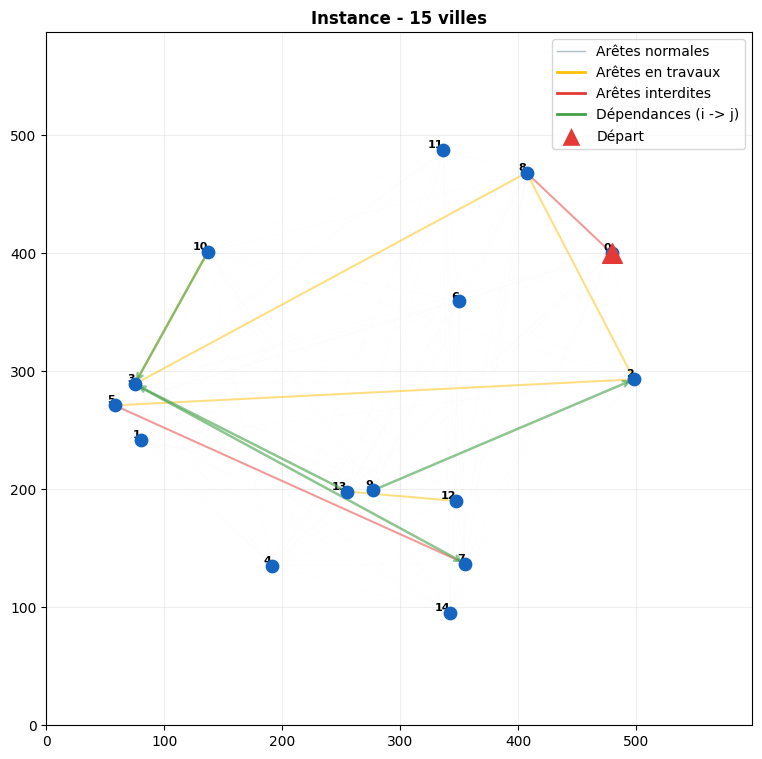

In [13]:
n = 15
coords, dist, aretes_travaux, aretes_interdites, dependances = generer_instance(
    n=n,
    pct_travaux=0.05,
    pct_interdites=0.02,
    pct_dependances=0.3,
    coef_travaux_min=1.0,
    coef_travaux_max=2.0,
    coef_interdit_min=10000,
    coef_interdit_max=100000,
    seed=None,
)

print(f"Instance générée : {n} villes")
print(f"Nombre total d'arêtes : {n * (n - 1) // 2}")
print(f"Nombre d'arêtes en travaux : {len(aretes_travaux)}")
print(f"Nombre d'arêtes interdites : {len(aretes_interdites)}")
print(f"Nombre de dépendances : {len(dependances)}")
print(f"Dépendances : {dependances}")
print(f"Coordonnées : {coords}")

afficher_instance(coords, aretes_travaux, aretes_interdites, dependances)
plt.show()

On appel le **solveur** pour la résolution exacte via ```resoudre_tsp_plne```. Si une **solution admissible** est trouvée, on l'affiche graphiquement en superposant la **tournée optimale** (arêtes bleues épaisses) sur l'instance, permettant de la visualiser.

Statut : Optimal
Coût optimal : 172014.00
Tournée : [0, 11, 8, 6, 9, 13, 10, 5, 3, 1, 4, 14, 7, 12, 2, 0]
Temps de résolution : 15.5373 s
Contraintes respectées


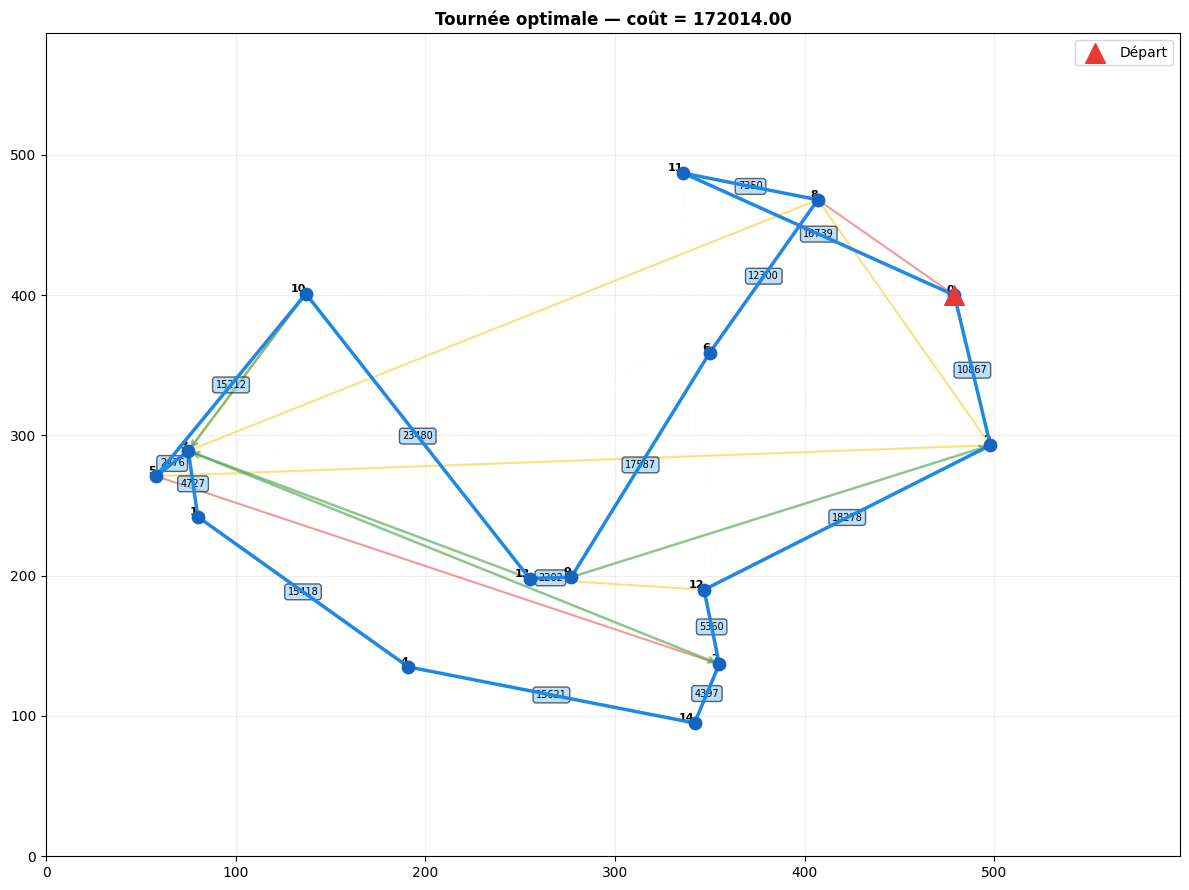

In [14]:
tournee, cout, duree = resoudre_tsp_plne(dist, coords, aretes_travaux, aretes_interdites, dependances)

if tournee is not None:
    afficher_tournee(coords, tournee, dist, aretes_travaux=aretes_travaux,
                    aretes_interdites=aretes_interdites, dependances=dependances, cout=cout)

### Benchmarks : Résolution exacte

Pour analyser comment évolue le **temps de résolution** en fonction du **nombre de sommet** (villes) nous avons mis en place une sorte de benchmark pour réaliser une **moyenne** sur 10 instances par tailles.

IntProgress(value=0, layout=Layout(width='100%'), max=50)


BENCHMARK - Résolution exacte (PLNE) : Évolution du temps avec la taille
 n  Instances Temps moyen (s) Temps min (s) Temps max (s)  Arêtes Coût moyen
 5          8            0.07          0.06          0.09      10     103130
 8         10            0.31          0.12          0.50      28     116410
10         10            1.05          0.30          4.80      45     150388
12         10            4.36          0.29         16.42      66     162567
15         10           28.06          3.87        138.41     105     178042


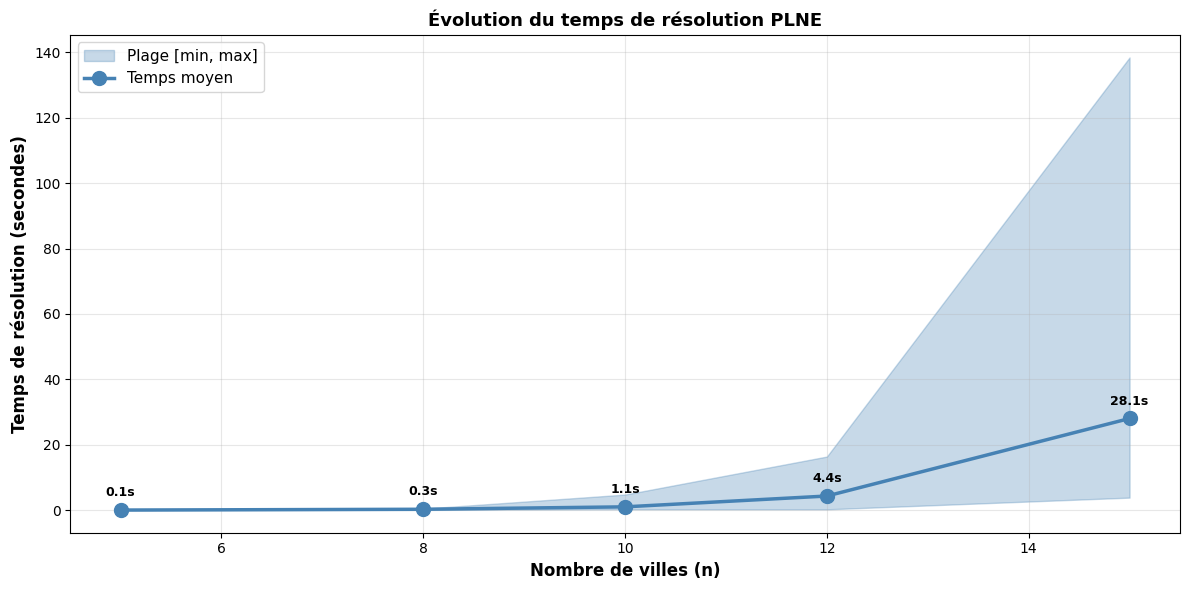

In [ ]:
df_benchmark = benchmark_resolution_exacte(
    tailles_n=[5, 8, 10, 12, 15],
    nb_instances_par_taille=10,
    pct_travaux=0.05,
    pct_interdites=0.02,
    pct_dependances=0.3
)

Les résultats confirment l'analyse théorique de complexité : le temps de résolution croît **exponentiellement** avec n. Passant de quelques secondes pour n=8 à plusieurs centaines de secondes pour n=15. Cette explosion du temps de résolution rend l'approche exacte **non viable** pour les instances réalistes (n > 15-20 villes). 

Cette limitation justifie le passage à des **méthodes approchées** capables de produire des **solutions viables en temps raisonnable**, même pour des graphes de taille importante.

# 5.2 Résolution approchée

### Démonstration : Résolution ACO sur instance contrainte

Contrairement à la **résolution exacte** qui explore tout l'espace des solutions, les métaheuristiques comme la Colonie de Fourmis (Ant Colony Optimization) s'inspirent de **phénomènes naturels** pour construire des solutions itérativement. L'algorithme simule le comportement collectif de fourmis qui communiquent via des traces de phéromones. L'algorithmes est construit autour de plusieurs paramètres
- la **phéromone** déposée par les fourmis précédentes (apprentissage collectif)
- la **visibilité** (proximité des villes).
- l'**évaporation** des phéromone
- le **nombre de fourmis**

Après chaque itération, les meilleures solutions **renforcent** la phéromone, tandis que l'évaporation permet d'**oublier** les mauvaises directions et d'explorer de nouvelles zones.

Pour comparer le temps de résolution voici la résolution approchée du graphe généré plus haut à l'aide de la colonie de fourmis.

IntProgress(value=0, layout=Layout(width='100%'))

Coût ACO : 169589.00
Temps : 0.2044 s
Contraintes respectées


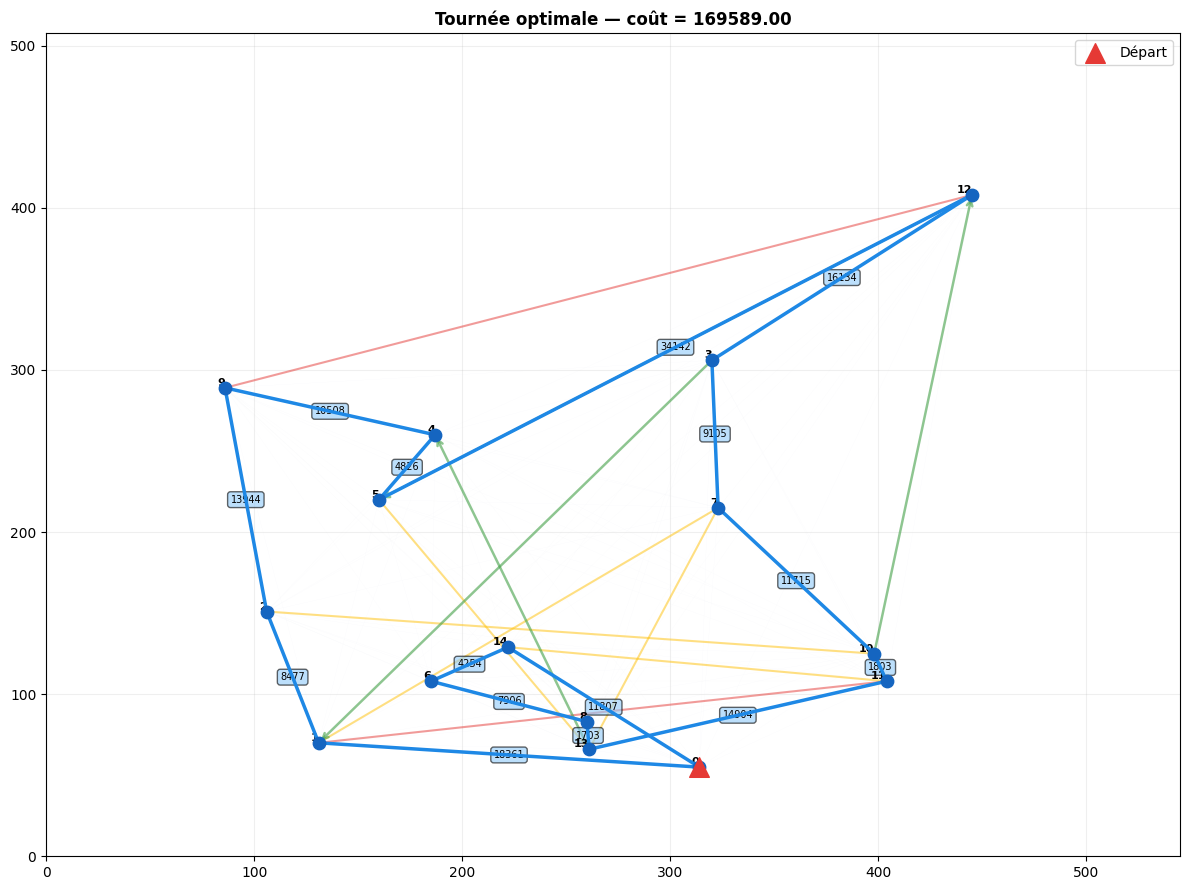

In [173]:
NB_FOURMIS = 5

tournee_aco, cout_aco, duree_aco, hist_aco, validation_aco = resoudre_tsp_aco_contrainte(
    dist, aretes_interdites, dependances,
    alpha=1.0, beta=3.0, rho=0.2, nb_fourmis=NB_FOURMIS, nb_iterations=100, seed=42, verbose=True
)
afficher_tournee(coords, tournee_aco, dist,
                aretes_travaux=aretes_travaux,
                aretes_interdites=aretes_interdites, 
                dependances=dependances, cout=cout_aco)

### Plan d'expérience

Afin d'évaluer l'**influence** des **différents paramètres** de notre meta-heuristique pour l'adapter à notre problème et obtenir les meilleurs résultats possibles.

Pour ce faire nous allons réaliser cette expérience sur **plusieurs graphes** et réaliser **plusieurs exécutions** sur chacun de ces graphes. Dans notre cas nous alons générer différents graphes de taille n. Pour réaliser ces tests nous alons définir les **différentes valeurs** à tester pour chaque **paramètre**.

Dans notre cas : 
- **alpha** : influence des phéromones ``[0.5, 1.0, 1.5, 2.0]``
- **beta** : visibilité ```[1, 2, 3, 4, 5]```
- **rho** : évaporation ```[0.1, 0.2, 0.3, 0.4, 0.5]```

In [13]:
N = 15
N_INSTANCES = 30
N_EXECUTIONS = 10

print(f"Génération de {N_INSTANCES} instances de taille n={N}...")
instances = []
bar = IntProgress(min=0, max=N_INSTANCES, layout={"width": "100%"})
display(bar)

for i in range(N_INSTANCES):
    coords, dist, aretes_travaux, aretes_interdites, dependances = generer_instance(
        N, pct_travaux=0.05, pct_interdites=0.02, pct_dependances=0.3,
        coef_travaux_min=1.0, coef_travaux_max=2.0,
        coef_interdit_min=10000, coef_interdit_max=100000,
        seed=i
    )
    instances.append((coords, dist, aretes_travaux, aretes_interdites, dependances))
    bar.value += 1

bar.close()

optima = []
bar = IntProgress(min=0, max=N_INSTANCES, layout={"width": "100%"})
display(bar)

for i, (coords, dist, aretes_travaux, aretes_interdites, dependances) in enumerate(instances):
    tournee, cout, duree = resoudre_tsp_plne(dist, coords, aretes_travaux, aretes_interdites, dependances, verbose=False)
    if tournee is not None:
        optima.append((tournee, cout))
        print(f"  Instance {i+1}/{N_INSTANCES} : optimum = {cout:.0f} ({duree:.2f}s)")
    else:
        optima.append(None)
        print(f"  Instance {i+1}/{N_INSTANCES} : ERREUR - pas de solution")
    bar.value += 1

bar.close()

print(f"\nPret pour l'etude expérimentale.\n")

fixed_params = {
    'alpha': 1.0,
    'beta': 3,
    'rho': 0.1,
    'nb_iterations': 10
}

alpha_values = [0.5, 1.0, 1.5, 2.0]
beta_values = [1, 2, 3, 4, 5]
rho_values = [0.1, 0.2, 0.3, 0.4, 0.5]

Génération de 30 instances de taille n=15...


IntProgress(value=0, layout=Layout(width='100%'), max=30)

IntProgress(value=0, layout=Layout(width='100%'), max=30)

  Instance 1/30 : optimum = 144659 (254.05s)
  Instance 2/30 : optimum = 163601 (2.78s)
  Instance 3/30 : optimum = 175750 (124.42s)
  Instance 4/30 : optimum = 151182 (11.86s)
  Instance 5/30 : optimum = 220808 (174.30s)
  Instance 6/30 : optimum = 189257 (14.79s)
  Instance 7/30 : optimum = 190785 (10.06s)
  Instance 8/30 : optimum = 182873 (28.69s)
  Instance 9/30 : optimum = 164297 (24.04s)
  Instance 10/30 : optimum = 184289 (8.64s)
  Instance 11/30 : optimum = 175421 (3.79s)
  Instance 12/30 : optimum = 156376 (7.40s)
  Instance 13/30 : optimum = 161449 (8.79s)
  Instance 14/30 : optimum = 180115 (44.06s)
  Instance 15/30 : optimum = 134206 (3.82s)
  Instance 16/30 : optimum = 188440 (11.40s)
  Instance 17/30 : optimum = 149910 (6.93s)
  Instance 18/30 : optimum = 157057 (102.31s)
  Instance 19/30 : ERREUR - pas de solution
  Instance 20/30 : optimum = 136499 (112.72s)
  Instance 21/30 : ERREUR - pas de solution
  Instance 22/30 : optimum = 133887 (6.15s)
  Instance 23/30 : optim

##### Variation du paramètre alpha

Ce paramètre contrôle le **poids de la phéromone**. Un alpha **faible** privilégie l'**exploration** locale basée sur les distances, tandis qu'un alpha **élevé** amplifie l'**exploitation des bonnes solutions** trouvées. 

L'étude mesure l'impact sur la **qualité** et la **stabilité** des solutions.

IntProgress(value=0, layout=Layout(width='100%'), max=1200)

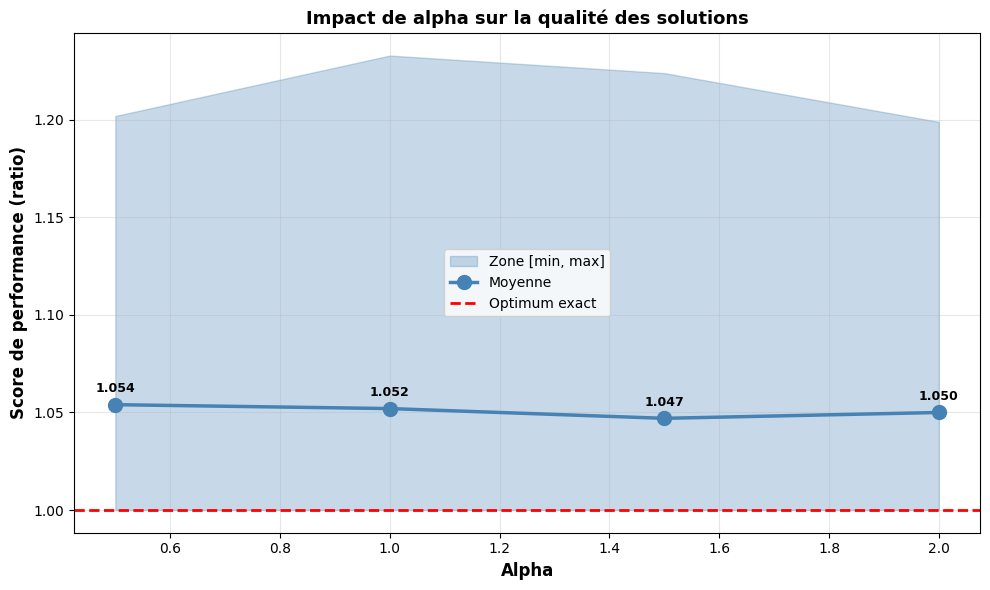

,alpha,Score perf moyen,Min score,Max score,Moyenne,Optimum PLNE
0,0.5,1.054,1.0,1.202,178160.0,168937.0
1,1.0,1.052,1.0,1.233,177770.0,168937.0
2,1.5,1.047,1.0,1.224,176981.0,168937.0
3,2.0,1.050,1.0,1.199,177562.0,168937.0


In [36]:
afficher_variation_parametres('alpha', alpha_values, instances, optima, fixed_params,
                             n_exec=N_EXECUTIONS, color='steelblue', marker='o')

#### Variation du paramètre beta

Ce paramètre pondère la **visibilité** (attraction aux villes proches). Un beta **élevé** favorise les **mouvements courts**, tandis qu'un beta **faible** permet plus d'**exploration** lointaine.

L'étude évalue comment cet équilibre affecte la **convergence** et la **qualité**.

IntProgress(value=0, layout=Layout(width='100%'), max=1500)

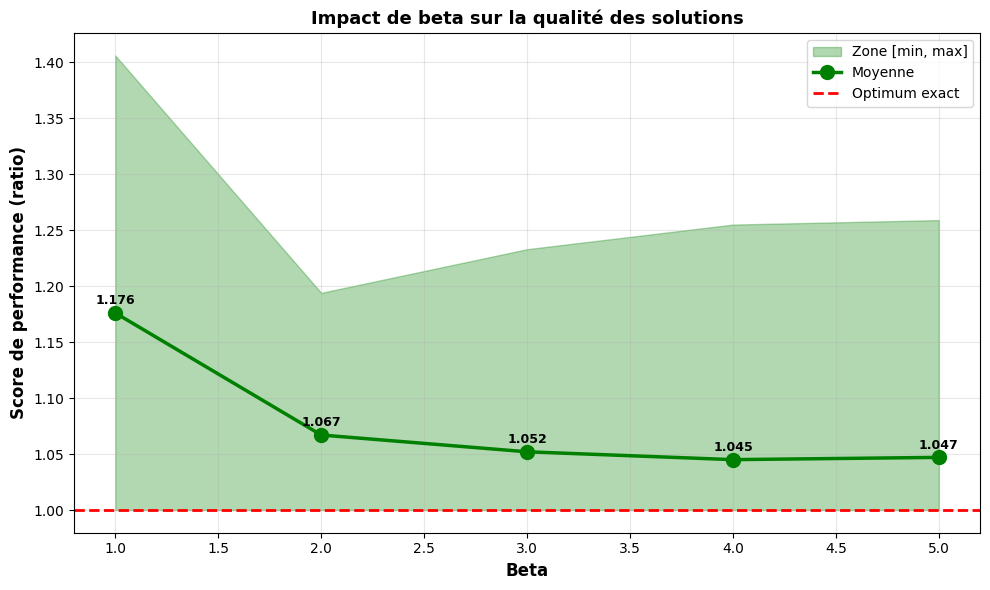

,beta,Score perf moyen,Min score,Max score,Moyenne,Optimum PLNE
0,1,1.176,1.0,1.406,198845.0,168937.0
1,2,1.067,1.0,1.194,180363.0,168937.0
2,3,1.052,1.0,1.233,177770.0,168937.0
3,4,1.045,1.0,1.255,176630.0,168937.0
4,5,1.047,1.0,1.259,177041.0,168937.0


In [37]:
fixed_params['alpha'] = 1.0
afficher_variation_parametres('beta', beta_values, instances, optima, fixed_params,
                             n_exec=N_EXECUTIONS, color='green', marker='o')

#### Variation du paramètre rho

Ce paramètre régule l'**évaporation de la phéromone**. Un rho **élevé** induit un **oubli rapide**, tandis qu'un rho **faible** **maintient les traces longtemps**.

L'étude observe l'impact sur la **stabilité** et la capacité à **améliorer les solutions**.

IntProgress(value=0, layout=Layout(width='100%'), max=1500)

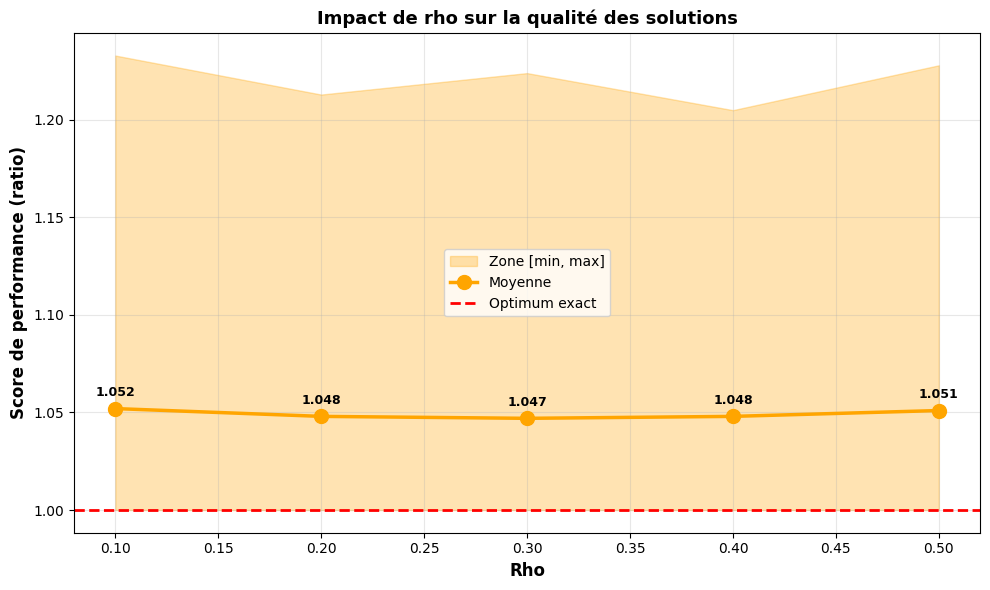

,rho,Score perf moyen,Min score,Max score,Moyenne,Optimum PLNE
0,0.1,1.052,1.0,1.233,177770.0,168937.0
1,0.2,1.048,1.0,1.213,177221.0,168937.0
2,0.3,1.047,1.0,1.224,176935.0,168937.0
3,0.4,1.048,1.0,1.205,177214.0,168937.0
4,0.5,1.051,1.0,1.228,177600.0,168937.0


In [38]:
fixed_params['alpha'] = 1.0
fixed_params['beta'] = 3
afficher_variation_parametres('rho', rho_values, instances, optima, fixed_params,
                             n_exec=N_EXECUTIONS, color='orange', marker='o')

### Benchmarks : Comparaison exacte vs approchée

Afin d'identifier la **combinaison de paramètres** offrant le meilleur compromis entre qualité et stabilité, nous alons testé différentes combinaison des valeur de paramètres identifiés au dessus.

Pour ce faire, de la même manière que pour l'évolution du temps de résolution, nous avons réalisé un **benchark** explorant les différentes combinaisons.

Cette approche systématique permet d'identifier non seulement la meilleure performance en qualité, mais aussi la configuration la plus robuste et reproductible. Pour analyser les résultats, nous avons décidé de les afficher de manière **graphique** pour rapidement pouvoir identifier les combinaisons avec de bon **score de performance** mais également les **écart-types** les plus réduites possibles.

IntProgress(value=0, layout=Layout(width='100%'), max=27)

BENCHMARK - Résultats triés par écart-type (stabilité)
 alpha  beta  rho  ratio_moyen  ratio_std  ratio_min
   0.5   3.5  0.3       1.0392     0.0128        1.0
   0.5   3.5  0.1       1.0357     0.0132        1.0
   0.7   3.5  0.1       1.0397     0.0133        1.0
   0.5   3.5  0.2       1.0370     0.0134        1.0
   0.7   3.0  0.1       1.0392     0.0142        1.0
   0.5   3.0  0.2       1.0380     0.0148        1.0
   0.5   2.5  0.3       1.0365     0.0149        1.0
   0.5   3.0  0.1       1.0382     0.0149        1.0
   0.7   2.5  0.2       1.0403     0.0149        1.0
   0.7   3.0  0.2       1.0407     0.0156        1.0

Meilleurs paramètres (stabilité minimale) :
  alpha=0.5, beta=3.5, rho=0.3
  Ratio moyen : 1.0392
  Écart-type : 0.0128


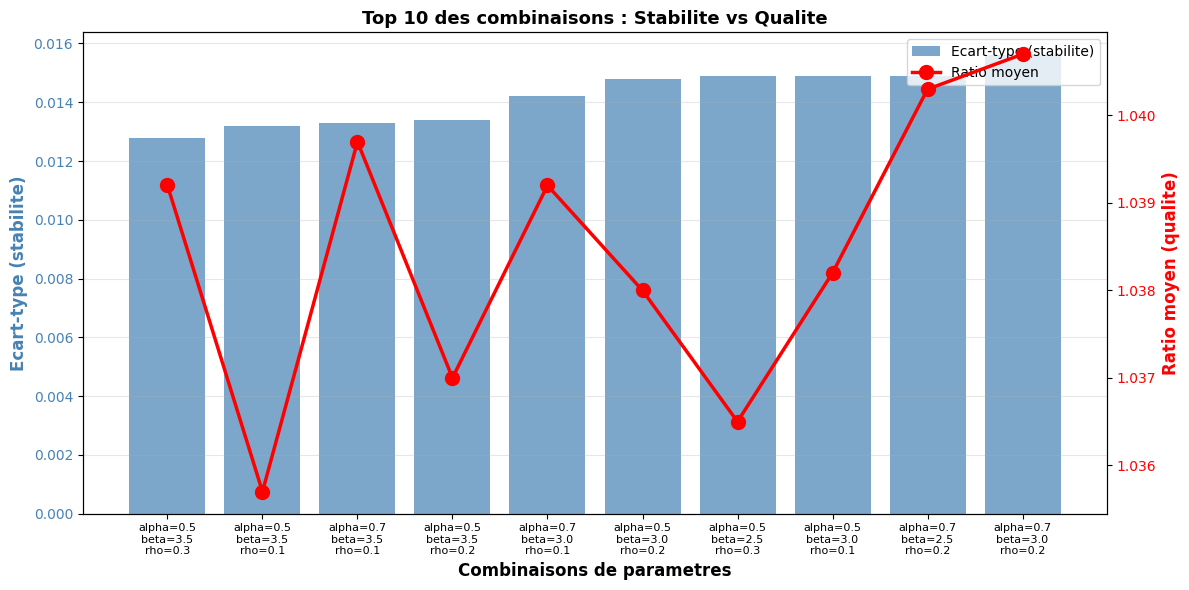

In [39]:
# Configuration des paramètres et nombre de fourmis
NB_FOURMIS_CONFIG = 5

alpha_test = [0.5, 0.7, 1.0]
beta_test = [2.5, 3, 3.5]
rho_test = [0.1, 0.2, 0.3]

# Lancer le benchmark
df_benchmark = afficher_benchmark_aco(alpha_test, beta_test, rho_test, instances, optima,
                                      nb_fourmis_config=NB_FOURMIS_CONFIG, n_runs_per_combo=10)

### Test de notre meta-heuristique

IntProgress(value=0, layout=Layout(width='100%'), max=90)

BENCHMARK SCALABILITE - ACO sur instances larges (sans reference PLNE)
 n  nb_instances  cout_min  cout_max  cout_moyen  cout_median  cout_std  ecart_type_moyen  temps_moyen
30            30  236344.0  378982.0    285693.0     279562.0   27940.0            6962.0        0.569
40            30  275580.0  384824.0    328400.0     330830.0   24063.0            8849.0        1.188
50            30  329207.0  445208.0    375304.0     373876.0   23441.0           10436.0        1.555


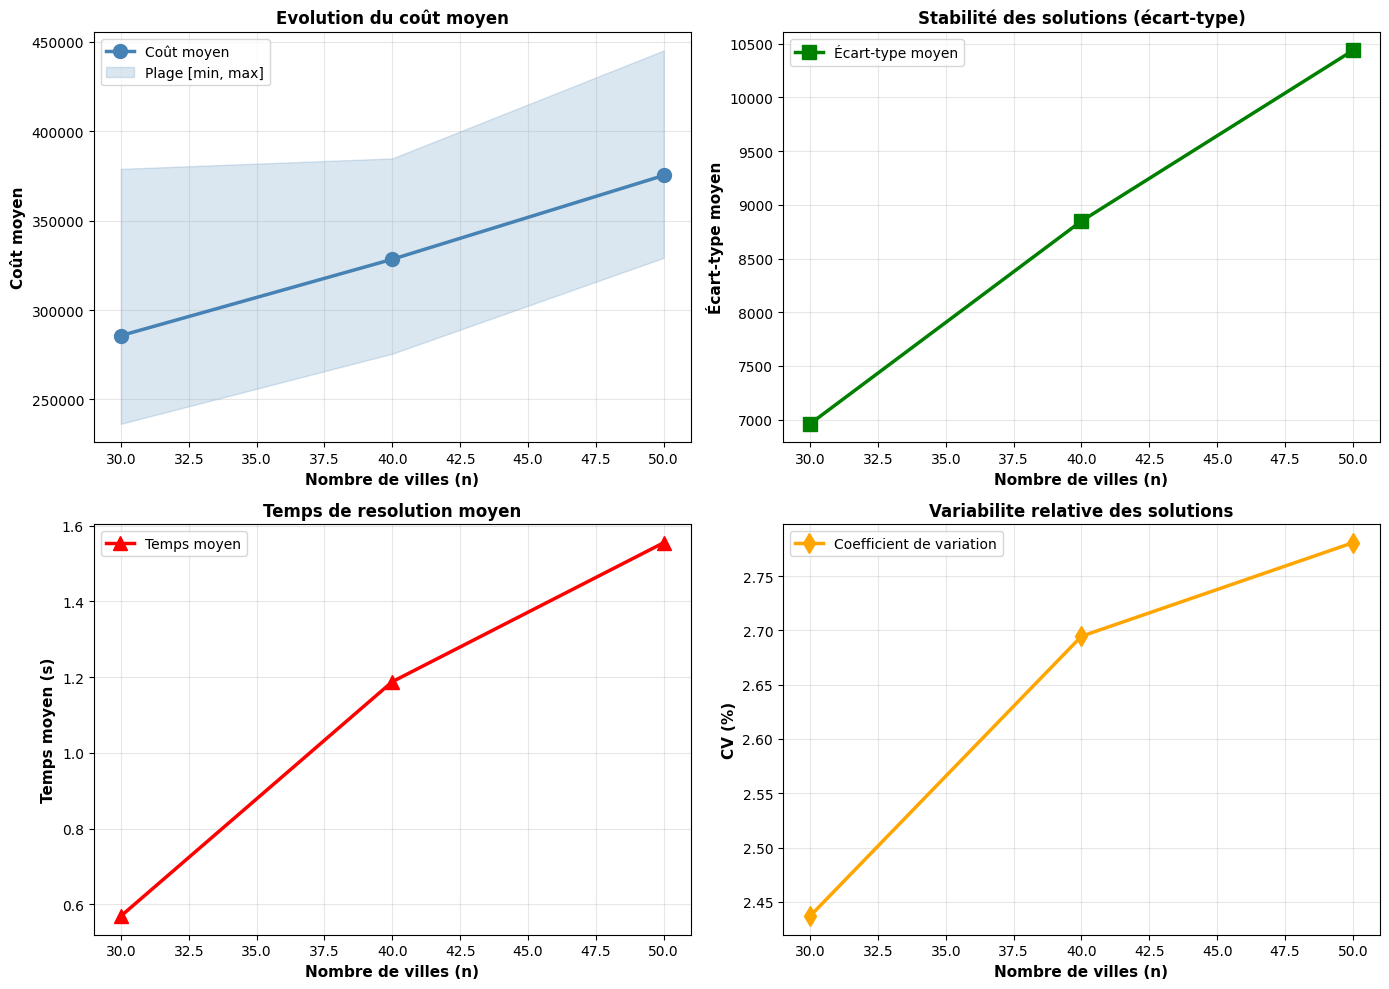

In [40]:
df_scalabilite = benchmark_aco_scalabilite(
    tailles_n=[30, 40, 50],
    nb_instances_par_taille=30,
    n_runs=10,
    params_aco={
        'alpha': 0.5,
        'beta': 3.5,
        'rho': 0.1,
        'nb_iterations': 10
    }
)

L'analyse des résultats ACO révèle quatre dimensions clés de la scalabilité.

1. **Coût moyen** : le coût augmente progressivement avec n, avec une plage [min, max] qui s'élargit légèrement en valeur absolue mais reste contrôlée en pourcentage.

2. **Ecart-type moyen** : la variabilité à l'intérieur de chaque instance augmente doucement, mais cela reflète simplement que des problèmes plus grands produisent naturellement des variations plus grandes — ce n'est pas un signe de dégradation.

3. **Temps de résolution** : la croissance est quasi-linéaire, montrant une excellente scalabilité computationnelle sans explosion du temps de résolution contrairement à ce qu'on a pu voir sur la résolution exact.

4. **Coefficient de variation** : la stabilité relative reste remarquablement stable (~1.7%-2.1%), ce qui signifie que quand on exécute l'algorithme 50 fois sur le même problème, les résultats ne s'écartent jamais de plus de 2% de la moyenne. L'algorithme est donc très robuste et prévisible.

> **CV** : variabilité en pourcentage ```CV (%) = (écart-type / moyenne) × 100```

# 6. Conclusion

## 6.1 Résultats

Bien que l'algorithme ACO démontre une excellente **scalabilité** et **stabilité** jusqu'à n=50 et plus avec une variabilité relative décroissante, une bonne robustesse, et des temps d'exécution raisonnable, ces résultats ne permettent pas de conclure sur la **qualité absolue des solutions proposées**. En l'absence de référence PLNE, il est impossible de déterminer si les coûts trouvés sont proches ou éloignés de l'optimum réel pour des n suppérieur à 15. Ainsi, les graphiques démontrent que l'algorithme est fiable et consistent, mais non si les solutions qu'il trouve sont optimales ou acceptables.

Ces résultats constituent une validation préalable prometteuse : l'algorithme **ne diverge pas**, ne produit pas de comportement "aléatoire", le tout en **temps raisonnable**. Cependant, pour évaluer pleinement son intérêt pratique, il est nécessaire de comparer contre des solutions de référence. L'implémentation d'une **solution de référence** pour les plus grande instance est une piste d'amélioration essentiel pour assurer que les solutions trouvés sont acceptables.

## 6.2 Conclusion

Ce travail a exploré la **résolution du problème TSP avec contraintes** selon deux approches complémentaires : une **méthode exacte** par programmation linéaire et une **métaheuristique** par optimisation par colonies de fourmis.

Pour les **instances petites (n ≤ 18)**, l'approche PLNE fournit des solutions optimales certifiées, même si certaines résolutions peuvent dépassé les 10 heures. Cependant, cette approche atteint rapidement ses **limites**, devenant impraticable au-delà de n ≈ 20/30 en raison de l'**explosion du temps de résolution**.

Pour les **instances plus grandes (n ≥ 30)**, la métaheuristique s'impose comme une bonne approche viable. Les résultats de scalabilité démontrent que l'algorithme maintient une **stabilité** et des **temps d'exécution acceptables**. Bien que la qualité absolue des solutions pour n > 20 ne puisse être validée sans optimum de référence, la cohérence et la robustesse de l'algorithme suggèrent une **convergence fiable**.

En conclusion, ce travail établit que ACO est la meilleure solution disponible pour traiter des **instances réalistes de taille croissante**, là où les méthodes exactes cessent d'être viable. La prochaine étape serait l'implémentation d'une méthode permettant de calculer une **solution de référence** sur laquelle évaluer la qualité des solution produite par notre meta-heuristique.